<a href="https://colab.research.google.com/github/nikita082000/DTEY/blob/%D0%9C%D0%9D/%D0%9B%D0%A05_%D0%9D%D1%96%D0%BA%D0%B8%D1%82%D0%B5%D0%BD%D0%BA%D0%BE_4_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
# Імпортуйте необхідні бібліотеки
!pip install -q kagglehub

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import kagglehub

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler

In [2]:
# Завантажте датасет з Kaggle
path = kagglehub.dataset_download(
    "yug201/daily-climate-time-series-data-delhi-india"
)

print(path)

100%|██████████| 194k/194k [00:00<00:00, 40.9MB/s]

Extracting files...
/root/.cache/kagglehub/datasets/yug201/daily-climate-time-series-data-delhi-india/versions/1


In [3]:
# Зчитайте датасет у DataFrame та перегляньте дані
csv_path = os.path.join(
    path,
    "kaggel_weather_2013_to_2024.csv"
)

df = pd.read_csv(csv_path)

display(df.head())

print("Розмір:", df.shape)

print("\nНазви колонок:")
print(df.columns.tolist())

print("\nІнформація:")
df.info()

display(df.describe(include="all"))

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


Розмір: (3557, 29)

Назви колонок:
['Unnamed: 0', 'DATE', 'tempmax', 'tempmin', 'temp', 'feelslikemax', 'feelslikemin', 'feelslike', 'humidity', 'precip', 'precipprob', 'precipcover', 'windspeed', 'sealevelpressure', 'conditions', 'Year', 'month', 'dayofweek', 'dayofyear', 'year-2000', 'weekofyear', 'tempmax_humidity', 'tempmin_humidity', 'temp_humidity', 'feelslikemax_humidity', 'feelslikemin_humidity', 'feelslike_humidity', 'temp_range', 'heat_index']

Інформація:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   f

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,...,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
unique,NaN,3556,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,5/1/2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,1778.000000,NaN,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,...,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,1026.961781,NaN,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,...,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,0.000000,NaN,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,889.000000,NaN,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,...,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,1778.000000,NaN,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,...,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,2667.000000,NaN,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,...,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622


Підготовка даних

In [4]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу
df["DATE"] = pd.to_datetime(df["DATE"])

df = df.sort_values("DATE")

df = df.loc[
    :,
    ~df.columns.str.contains("^Unnamed")
]

df = df.set_index("DATE")

df.head()

,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [5]:
# Перегляньте інформацію про структуру датасету
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3557 non-null   float64
 1   tempmin                3557 non-null   float64
 2   temp                   3557 non-null   float64
 3   feelslikemax           3557 non-null   float64
 4   feelslikemin           3557 non-null   float64
 5   feelslike              3557 non-null   float64
 6   humidity               3557 non-null   float64
 7   precip                 3557 non-null   float64
 8   precipprob             3557 non-null   int64  
 9   precipcover            3557 non-null   float64
 10  windspeed              3557 non-null   float64
 11  sealevelpressure       3557 non-null   float64
 12  conditions             3557 non-null   object 
 13  Year                   3557 non-null   int64  
 14  month                  3557 non-null  

In [6]:
# Перевірте наявність пропущених значень
df.isna().sum()

,0
tempmax,0
tempmin,0
temp,0
feelslikemax,0
feelslikemin,0
feelslike,0
humidity,0
precip,0
precipprob,0
precipcover,0


Графік температури

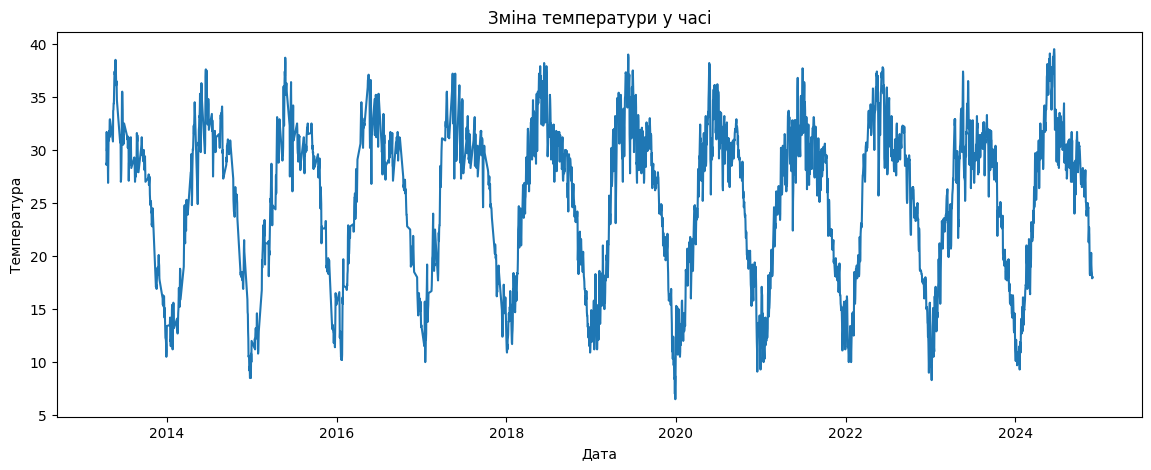

In [7]:
# Побудуйте графік зміни температури у часі
plt.figure(figsize=(14, 5))

plt.plot(df.index, df["temp"])

plt.xlabel("Дата")
plt.ylabel("Температура")
plt.title("Зміна температури у часі")

plt.show()

Ковзне середнє

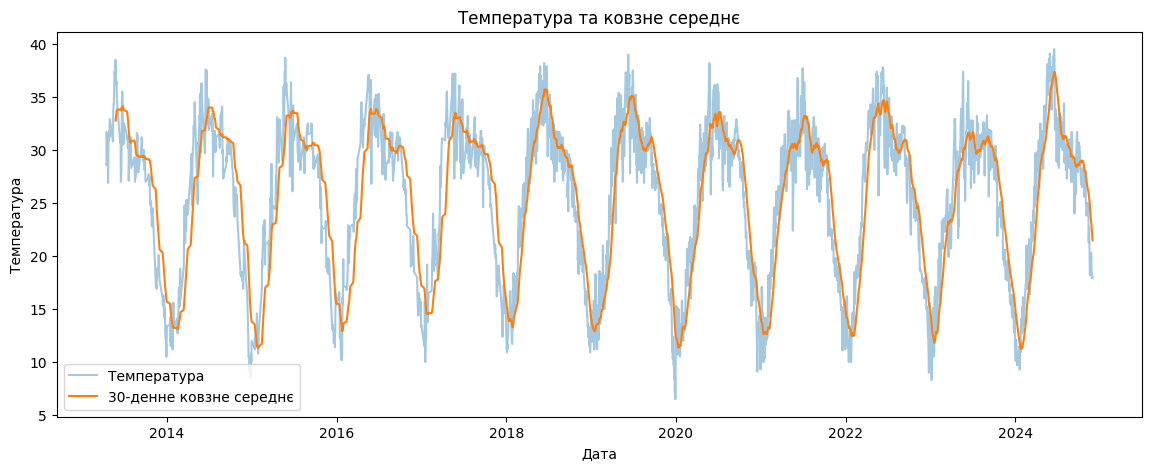

In [8]:
# Обчисліть та візуалізуйте ковзне середнє температури
rolling_mean = df["temp"].rolling(window=30).mean()

plt.figure(figsize=(14, 5))

plt.plot(df.index, df["temp"], label="Температура", alpha=0.4)
plt.plot(df.index, rolling_mean, label="30-денне ковзне середнє")

plt.xlabel("Дата")
plt.ylabel("Температура")
plt.title("Температура та ковзне середнє")
plt.legend()

plt.show()

Розподіл температури

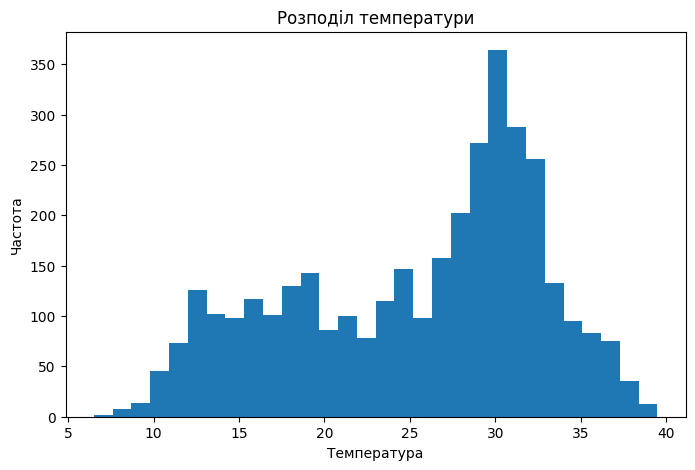

In [9]:
# Побудуйте гістограму розподілу температури
plt.figure(figsize=(8, 5))

plt.hist(df["temp"], bins=30)

plt.xlabel("Температура")
plt.ylabel("Частота")
plt.title("Розподіл температури")

plt.show()

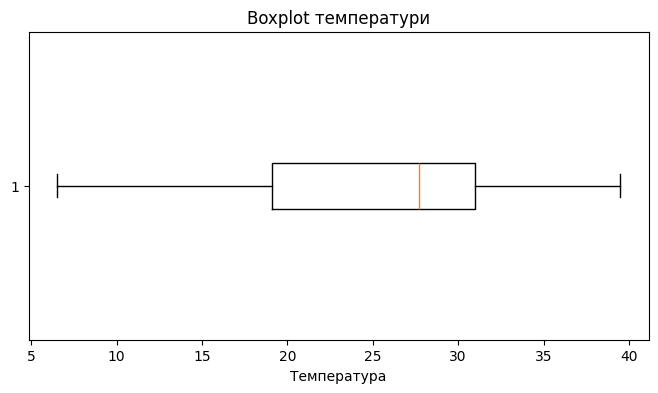

In [10]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure(figsize=(8, 4))

plt.boxplot(df["temp"], vert=False)

plt.xlabel("Температура")
plt.title("Boxplot температури")

plt.show()

Аналіз автокореляції
ACF

PACF

<Figure size 1200x500 with 0 Axes>

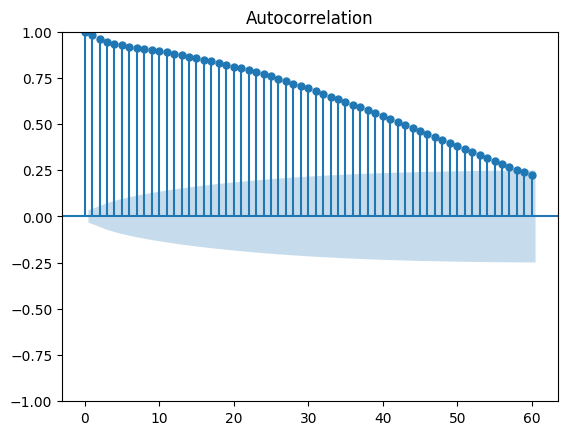

In [11]:
# Побудуйте графік автокореляційної функції (ACF)
plt.figure(figsize=(12, 5))

plot_acf(
    df["temp"],
    lags=60
)

plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

<Figure size 1200x500 with 0 Axes>

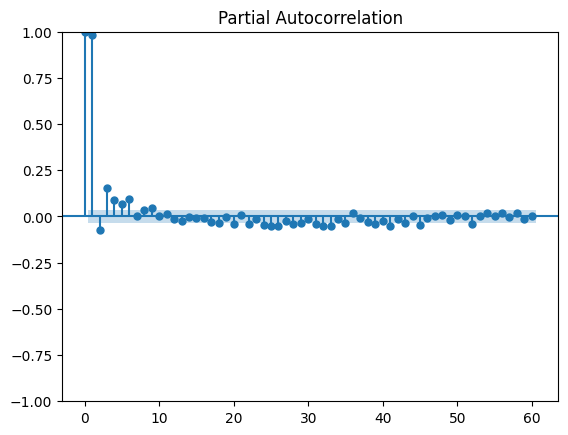

In [12]:
# Побудуйте графік часткової автокореляційної функції (PACF)
plt.figure(figsize=(12, 5))

plot_pacf(
    df["temp"],
    lags=60,
    method="ywm"
)

plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [13]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
series = df["temp"].copy()

split_index = int(len(series) * 0.8)

train = series.iloc[:split_index]
test = series.iloc[split_index:]

print("Train:", len(train))
print("Test:", len(test))

print("Train period:", train.index.min(), "-", train.index.max())
print("Test period:", test.index.min(), "-", test.index.max())

Train: 2845
Test: 712
Train period: 2013-04-14 00:00:00 - 2022-12-19 00:00:00
Test period: 2022-12-20 00:00:00 - 2024-11-30 00:00:00


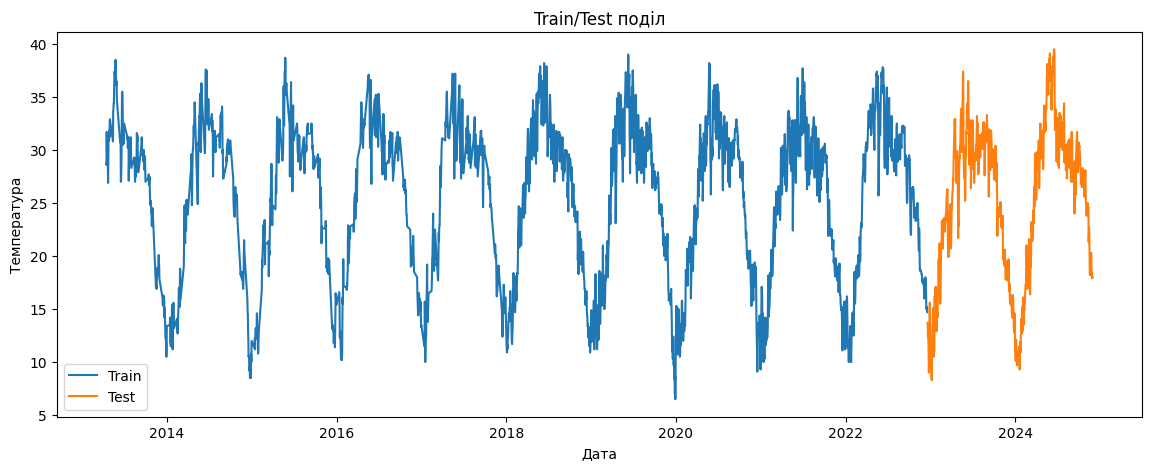

In [14]:
plt.figure(figsize=(14, 5))

plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Test")

plt.xlabel("Дата")
plt.ylabel("Температура")
plt.title("Train/Test поділ")
plt.legend()

plt.show()

ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [17]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
arima_model = ARIMA(
    train.to_numpy(),
    order=(7, 1, 1)
)

arima_result = arima_model.fit()

In [18]:
arima_pred = arima_result.forecast(
    steps=len(test)
)

arima_pred = pd.Series(
    arima_pred,
    index=test.index
)

arima_pred.head()

,0
DATE,
2022-12-20,14.883677
2022-12-21,15.038830
2022-12-22,15.172853
2022-12-23,15.226829
2022-12-24,15.251293


In [19]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 2845
Model:                 ARIMA(7, 1, 1)   Log Likelihood               -4966.913
Date:                Thu, 29 Oct 2026   AIC                           9951.825
Time:                        14:41:54   BIC                          10005.402
Sample:                             0   HQIC                          9971.149
                               - 2845                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6114      0.202      3.025      0.002       0.215       1.008
ar.L2         -0.2103      0.022     -9.732      0.000      -0.253      -0.168
ar.L3         -0.0181      0.042     -0.426      0.6

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

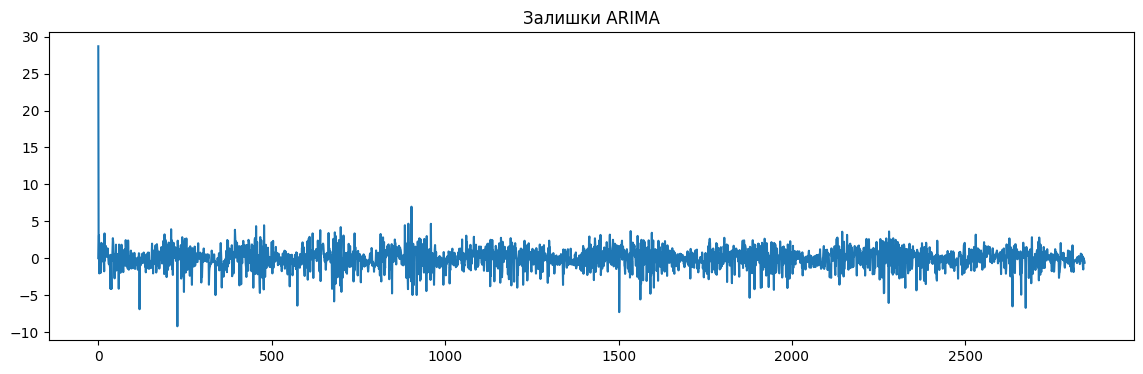

In [20]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
residuals = arima_result.resid

plt.figure(figsize=(14, 4))
plt.plot(residuals)
plt.title("Залишки ARIMA")
plt.show()

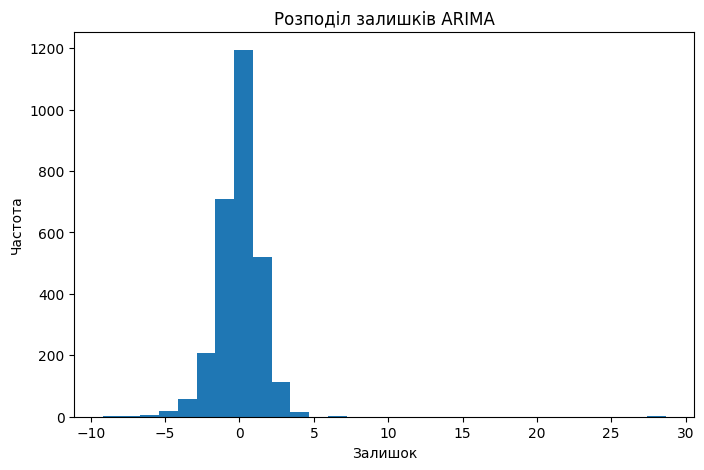

In [22]:
plt.figure(figsize=(8, 5))

plt.hist(residuals, bins=30)

plt.xlabel("Залишок")
plt.ylabel("Частота")
plt.title("Розподіл залишків ARIMA")

plt.show()

In [23]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
def mape(y_true, y_pred):
    return np.mean(
        np.abs((y_true - y_pred) / y_true)
    ) * 100

In [24]:
arima_mae = mean_absolute_error(
    test,
    arima_pred
)

arima_rmse = np.sqrt(
    mean_squared_error(test, arima_pred)
)

arima_mape = mape(
    test.to_numpy(),
    arima_pred.to_numpy()
)

print("MAE:", arima_mae)
print("RMSE:", arima_rmse)
print("MAPE:", arima_mape, "%")

MAE: 10.904888738851206
RMSE: 12.476120695457466
MAPE: 39.52015335390165 %


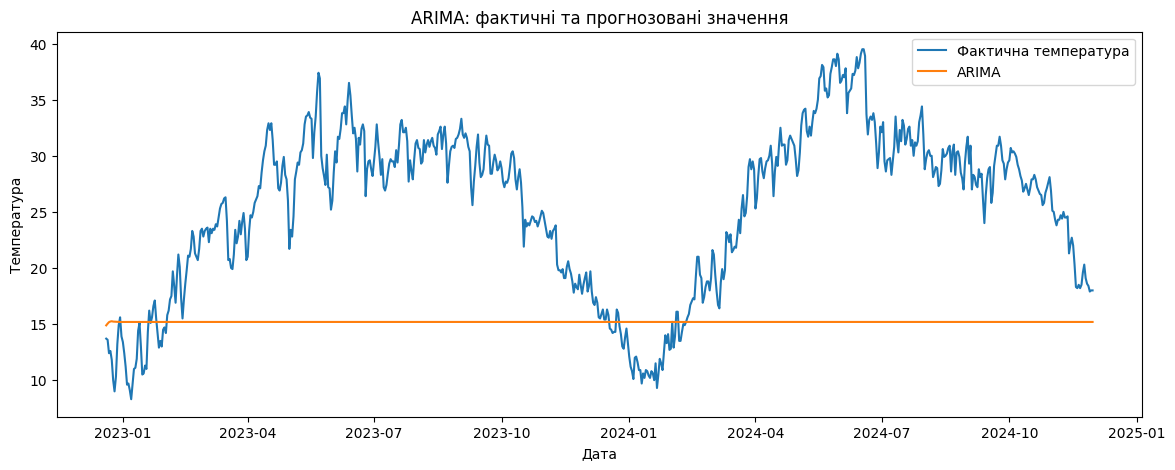

In [25]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize=(14, 5))

plt.plot(test.index, test, label="Фактична температура")
plt.plot(test.index, arima_pred, label="ARIMA")

plt.xlabel("Дата")
plt.ylabel("Температура")
plt.title("ARIMA: фактичні та прогнозовані значення")
plt.legend()

plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [26]:
!pip install -q prophet

from prophet import Prophet

In [27]:
# Підготуйте дані у форматі, необхідному для Prophet
prophet_train = pd.DataFrame({
    "ds": train.index,
    "y": train.values
})

prophet_test = pd.DataFrame({
    "ds": test.index,
    "y": test.values
})


In [28]:
# Створіть та навчіть модель Prophet
prophet_model = Prophet()

prophet_model.fit(prophet_train)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Прогноз

In [29]:
# Побудуйте прогноз Prophet для тестового періоду
future_test = pd.DataFrame({
    "ds": test.index
})

prophet_forecast = prophet_model.predict(future_test)

prophet_forecast[
    ["ds", "yhat", "yhat_lower", "yhat_upper"]
].head()

,ds,yhat,yhat_lower,yhat_upper
0,2022-12-20,13.892037,11.221588,16.541044
1,2022-12-21,13.738187,11.205006,16.194914
2,2022-12-22,13.534303,11.031937,16.081857
3,2022-12-23,13.344060,10.598246,15.841722
4,2022-12-24,13.189955,10.689605,15.822311


In [30]:
prophet_pred = pd.Series(
    prophet_forecast["yhat"].values,
    index=test.index
)

In [31]:
# Обчисліть MAE, RMSE, MAPE для Prophet
prophet_mae = mean_absolute_error(
    test,
    prophet_pred
)

prophet_rmse = np.sqrt(
    mean_squared_error(test, prophet_pred)
)

prophet_mape = mape(
    test.to_numpy(),
    prophet_pred.to_numpy()
)

print("MAE:", prophet_mae)
print("RMSE:", prophet_rmse)
print("MAPE:", prophet_mape, "%")

MAE: 2.004679994301011
RMSE: 2.5901965298397274
MAPE: 9.027934868552647 %


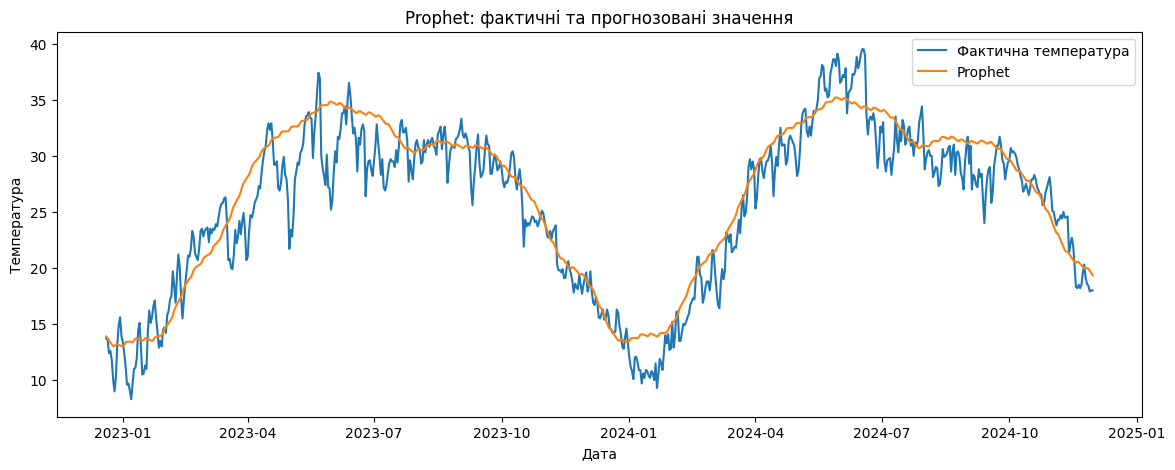

In [32]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(14, 5))

plt.plot(
    test.index,
    test,
    label="Фактична температура"
)

plt.plot(
    test.index,
    prophet_pred,
    label="Prophet"
)

plt.xlabel("Дата")
plt.ylabel("Температура")
plt.title("Prophet: фактичні та прогнозовані значення")
plt.legend()

plt.show()

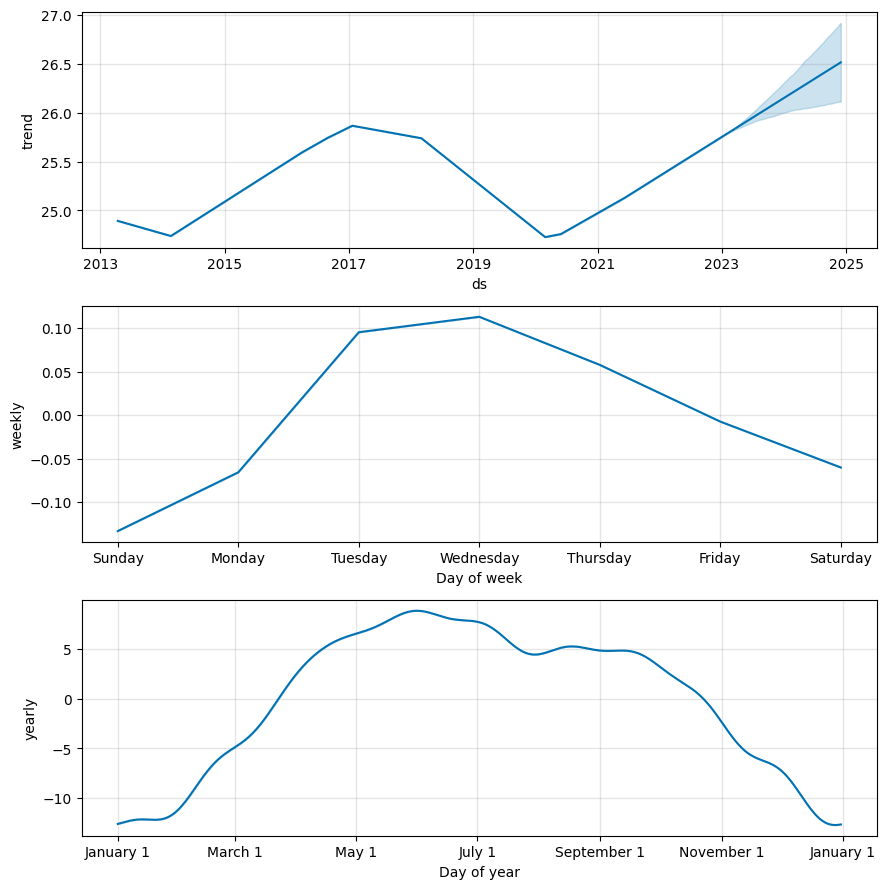

In [33]:
# Побудуйте компоненти моделі Prophet
prophet_all_dates = pd.DataFrame({
    "ds": series.index
})

prophet_forecast_all = prophet_model.predict(
    prophet_all_dates
)

prophet_model.plot_components(
    prophet_forecast_all
)

plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [34]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

lookback = 30

scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(
    train.to_numpy().reshape(-1, 1)
)

test_scaled = scaler.transform(
    test.to_numpy().reshape(-1, 1)
)

In [35]:
def create_sequences(data, lookback):
    X, y = [], []

    for i in range(lookback, len(data)):
        X.append(data[i - lookback:i])
        y.append(data[i])

    return np.array(X), np.array(y)

In [36]:
X_train_lstm, y_train_lstm = create_sequences(
    train_scaled,
    lookback
)

print(X_train_lstm.shape)
print(y_train_lstm.shape)

(2815, 30, 1)
(2815, 1)


In [37]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
test_input = np.vstack([
    train_scaled[-lookback:],
    test_scaled
])

X_test_lstm, y_test_lstm = create_sequences(
    test_input,
    lookback
)

print(X_test_lstm.shape)
print(y_test_lstm.shape)

(712, 30, 1)
(712, 1)


In [38]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
lstm_model = Sequential([
    Input(shape=(lookback, 1)),
    LSTM(50),
    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mse"
)

In [39]:
# Навчіть LSTM-модель
history = lstm_model.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)

Epoch 1/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0257 - val_loss: 0.0060
Epoch 2/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0058 - val_loss: 0.0047
Epoch 3/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0051 - val_loss: 0.0042
Epoch 4/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0046 - val_loss: 0.0042
Epoch 5/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0043 - val_loss: 0.0041
Epoch 6/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0041 - val_loss: 0.0040
Epoch 7/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0040 - val_loss: 0.0038
Epoch 8/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0039 - val_loss: 0.0036
Epoch 9/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0037 - val_loss: 0.0034
Epoch 10/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0036 - val_loss: 0.0032
Epoch 11/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0035 - val_loss: 0.0030
Epoch 12/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0034 - val_l

In [40]:
# Виведіть структуру LSTM-моделі
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,355 (122.48 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 20,904 (81.66 KB)

In [42]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
lstm_pred_scaled = lstm_model.predict(
    X_test_lstm
)

lstm_pred = scaler.inverse_transform(
    lstm_pred_scaled
).ravel()

lstm_actual = scaler.inverse_transform(
    y_test_lstm
).ravel()

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


In [43]:
# Сформуйте часові мітки для тестового прогнозу LSTM
lstm_dates = test.index

print(len(lstm_dates))
print(len(lstm_pred))

712
712


In [44]:
# Обчисліть MAE, RMSE, MAPE для LSTM
lstm_mae = mean_absolute_error(
    lstm_actual,
    lstm_pred
)

lstm_rmse = np.sqrt(
    mean_squared_error(lstm_actual, lstm_pred)
)

lstm_mape = mape(
    lstm_actual,
    lstm_pred
)

print("MAE:", lstm_mae)
print("RMSE:", lstm_rmse)
print("MAPE:", lstm_mape, "%")

MAE: 1.061660661054461
RMSE: 1.3595947761262928
MAPE: 4.53571886535026 %


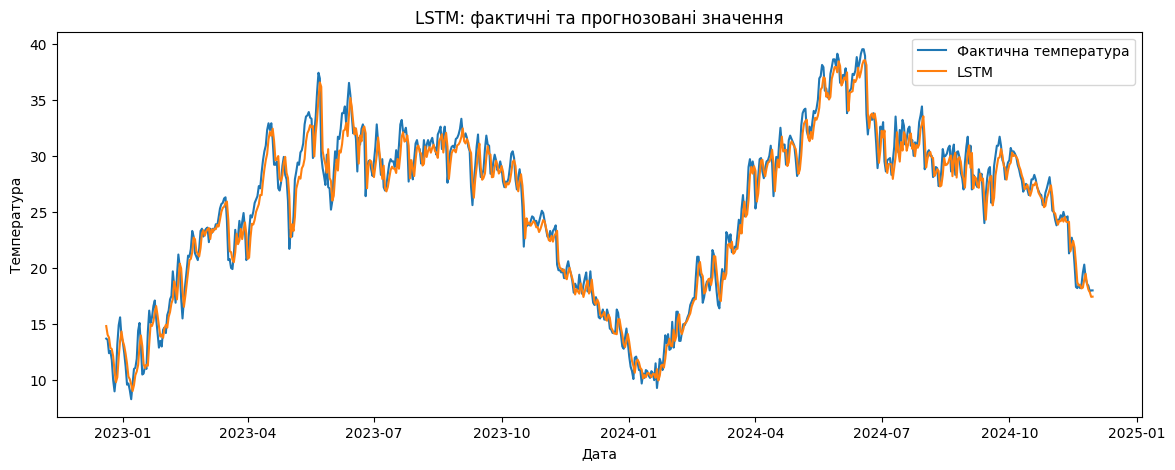

In [45]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize=(14, 5))

plt.plot(
    lstm_dates,
    lstm_actual,
    label="Фактична температура"
)

plt.plot(
    lstm_dates,
    lstm_pred,
    label="LSTM"
)

plt.xlabel("Дата")
plt.ylabel("Температура")
plt.title("LSTM: фактичні та прогнозовані значення")
plt.legend()

plt.show()

Порівняння моделей

In [46]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами
comparison = pd.DataFrame({
    "Model": ["ARIMA", "Prophet", "LSTM"],
    "MAE": [
        arima_mae,
        prophet_mae,
        lstm_mae
    ],
    "RMSE": [
        arima_rmse,
        prophet_rmse,
        lstm_rmse
    ],
    "MAPE (%)": [
        arima_mape,
        prophet_mape,
        lstm_mape
    ]
})

comparison = comparison.sort_values(
    "MAE"
).reset_index(drop=True)

comparison

,Model,MAE,RMSE,MAPE (%)
0,LSTM,1.061661,1.359595,4.535719
1,Prophet,2.004680,2.590197,9.027935
2,ARIMA,10.904889,12.476121,39.520153


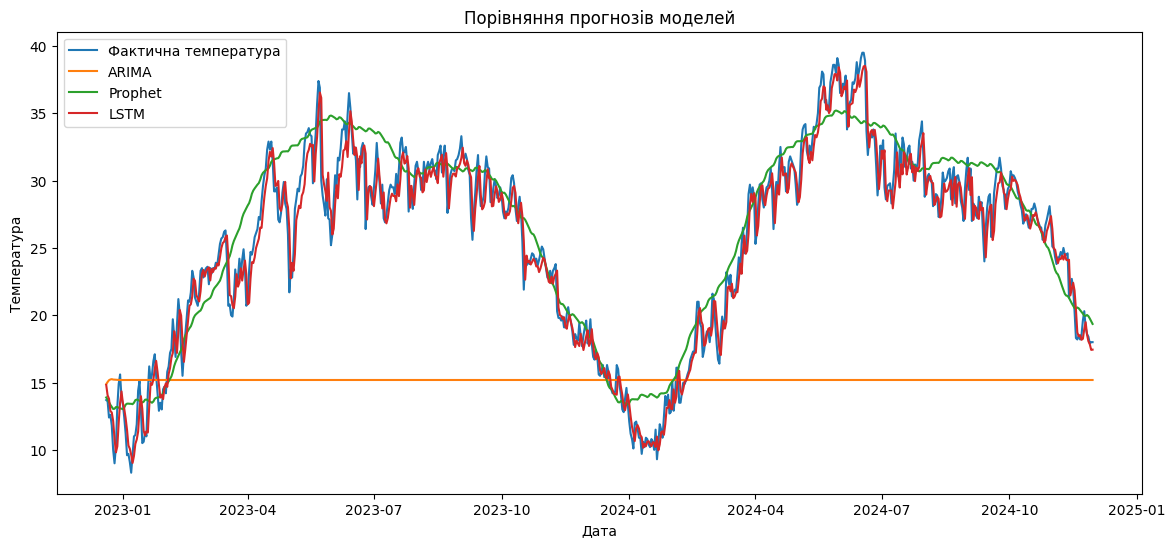

In [47]:
plt.figure(figsize=(14, 6))

plt.plot(
    test.index,
    test,
    label="Фактична температура"
)

plt.plot(
    test.index,
    arima_pred,
    label="ARIMA"
)

plt.plot(
    test.index,
    prophet_pred,
    label="Prophet"
)

plt.plot(
    lstm_dates,
    lstm_pred,
    label="LSTM"
)

plt.xlabel("Дата")
plt.ylabel("Температура")
plt.title("Порівняння прогнозів моделей")
plt.legend()

plt.show()

## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.


У лабораторній роботі було виконано аналіз часового ряду температури, досліджено його розподіл, ковзне середнє та автокореляційні залежності за допомогою ACF і PACF. Для прогнозування температури було побудовано три моделі: ARIMA, Prophet та LSTM.

Найгірший результат показала модель ARIMA: MAE = 10.90, RMSE = 12.48 та MAPE = 39.52%. Значно кращі результати отримано за допомогою Prophet, для якої MAE = 2.00, RMSE = 2.59 та MAPE = 9.03%. Найкращу якість прогнозування продемонструвала модель LSTM з MAE = 1.06, RMSE = 1.36 та MAPE = 4.54%.

Таким чином, за всіма використаними метриками LSTM є найточнішою моделлю серед досліджених. Prophet також добре відтворює часову динаміку температури, однак поступається LSTM. Обрана конфігурація ARIMA виявилася недостатньо ефективною для цього часового ряду. Отже, для прогнозування температури на досліджених даних найбільш доцільною серед побудованих моделей є LSTM.